# Nonlinear diffusion and reaction on the unit square

Find the scalar field $u$ on $\Omega=(0,1)^2$ from

$$
-\nabla\cdot\bigl[k(u)\nabla u\bigr]+c(\boldsymbol x)u^3=f(\boldsymbol x),
\qquad k(u)=k_0(1+\nabla u\cdot\nabla u),\qquad u|_{\partial\Omega}=0.
$$

Take $k_0=1$ and $c(x,y)=1+x$. Choose $f$ so that
$u_{\mathrm{exact}}(x,y)=4x(1-x)y(1-y)$ solves the problem. We will write
the residual and its tangent explicitly, then pass both forms to DOLFINx.

Run the cells in order in the **Python (Finite Elements)** kernel.
The results and plots from a completed run are saved below.

## Mesh and boundary condition

Both trial and test functions belong to $V=W^{1,4}_0(\Omega)$. Continuous
piecewise-linear functions have piecewise-constant gradients, so those
with zero boundary values belong to $V$. In DOLFINx, create the full $P_1$
space, then prescribe zero at the boundary degrees of freedom to obtain
the subspace $\mathcal V_{h,0}$.

In [2]:
import numpy as np
import ufl
from mpi4py import MPI
from petsc4py import PETSc
from dolfinx import fem, mesh
from dolfinx.fem.petsc import NonlinearProblem

n = 12
domain = mesh.create_unit_square(MPI.COMM_SELF, n, n)
V = fem.functionspace(domain, ("Lagrange", 1))  # Full P1 space before imposing bc.
u = fem.Function(V)  # Starts at zero.
v = ufl.TestFunction(V)
w = ufl.TrialFunction(V)  # Direction for the Newton correction.

fdim = domain.topology.dim - 1
# Build edge-to-element connectivity so DOLFINx can find exterior edges.
domain.topology.create_connectivity(fdim, domain.topology.dim)
boundary = mesh.exterior_facet_indices(domain.topology)
boundary_dofs = fem.locate_dofs_topological(V, fdim, boundary)
bc = fem.dirichletbc(PETSc.ScalarType(0), boundary_dofs, V)

## Source for the exact solution

Substitute $u_{\mathrm{exact}}$ for $u$ on the left of the PDE and use the
result as $f$. The gradient and divergence below are spatial derivatives
of the known solution.

In [3]:
x, y = ufl.SpatialCoordinate(domain)
k0 = 1.0
c = 1 + x
u_exact = 4 * x * (1 - x) * y * (1 - y)

g_exact = ufl.grad(u_exact)
k_exact = k0 * (1 + ufl.dot(g_exact, g_exact))
f = -ufl.div(k_exact * g_exact) + c * u_exact**3
dx = ufl.Measure("dx", domain=domain)

## Residual and tangent

For $u,v\in V$, define the load form $\ell$ and the semilinear form $a$:

$$
\ell(v)=\int_\Omega fv\,d\boldsymbol x,\qquad
a(u;v)=\int_\Omega\bigl[k(u)\nabla u\cdot\nabla v+cu^3v\bigr]\,d\boldsymbol x.
$$

Both forms are finite for $c\in L^\infty(\Omega)$ and $f\in L^{4/3}(\Omega)$.
Define the residual by $R(u;v)=\ell(v)-a(u;v)$.

Hold $v$ fixed and perturb $u$ in the direction $w\in V$. The two diffusion
terms come from differentiating $\nabla u$ and $k(u)$, respectively:

$$
\delta_u R(u;v)[w]=-\int_\Omega\left[
k(u)\nabla w\cdot\nabla v
+2k_0(\nabla u\cdot\nabla w)(\nabla u\cdot\nabla v)
+3cu^2wv
\right]\,d\boldsymbol x.
$$

In [4]:
g = ufl.grad(u)
gv = ufl.grad(v)
gw = ufl.grad(w)
k = k0 * (1 + ufl.dot(g, g))

ell = f * v * dx
a = (k * ufl.dot(g, gv) + c * u**3 * v) * dx
residual = ell - a

tangent = -(
    k * ufl.dot(gw, gv)
    + 2 * k0 * ufl.dot(g, gw) * ufl.dot(g, gv)
    + 3 * c * u**2 * w * v
) * dx

## Nonlinear solve

At each iteration the Newton correction satisfies
$\delta_u R(u_h^k;v_h)[\Delta u_h^k]=-R(u_h^k;v_h)$ for every
$v_h\in\mathcal V_{h,0}$. DOLFINx assembles both forms and imposes the boundary
condition. PETSc runs Newton with backtracking and uses a direct LU solve for
each small linear system. The relative residual tolerance is `1e-10`.
If PETSc reports failure to converge, the solve raises an error.

In [5]:
solver_options = {
    "snes_type": "newtonls",
    "snes_linesearch_type": "bt",
    "snes_rtol": 1e-10,
    "snes_error_if_not_converged": True,
    "ksp_type": "preonly",
    "pc_type": "lu",
}
problem = NonlinearProblem(
    residual, u, bcs=[bc], J=tangent,
    petsc_options_prefix="diffusion_", petsc_options=solver_options,
)
u.x.array[:] = 0.0  # Reset the initial guess if this cell is run again.
problem.solve()
print(f"Newton iterations: {problem.solver.getIterationNumber()}")

Newton iterations: 7


## Comparison with the exact solution

Compute the $L^2(\Omega)$ error by integrating $(u_h-u_{\mathrm{exact}})^2$
and taking its square root. The plots then show the mesh and the two
solutions on a shared color scale. Run the mesh plot first: the solution
plot uses the same triangulation.

In [6]:
error_sq = fem.assemble_scalar(fem.form((u - u_exact)**2 * dx))
print(f"L2 error: {np.sqrt(error_sq):.4e}")

L2 error: 2.1808e-03


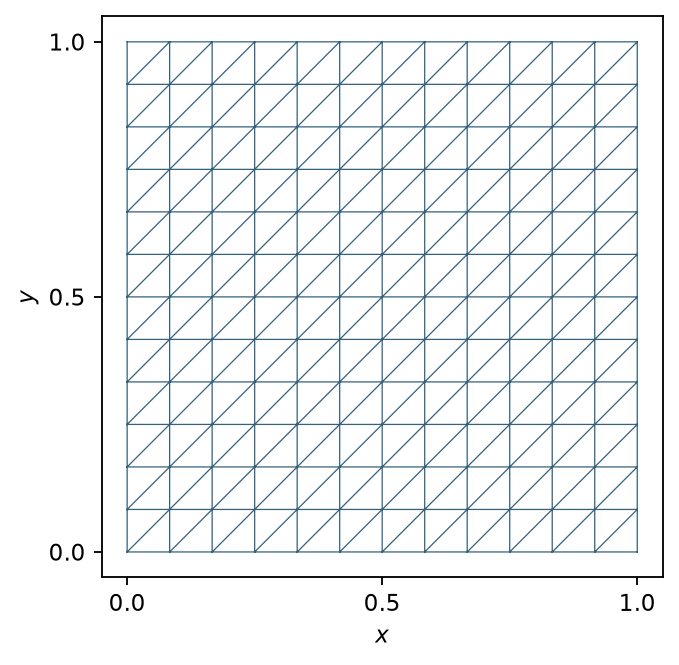

In [7]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from dolfinx import plot

# DOLFINx returns the plotting points in the order of the P1 degrees of freedom.
cells, _, points = plot.vtk_mesh(V)
triangles = cells.reshape(-1, 4)[:, 1:]  # Each row starts with the vertex count, 3.
triangulation = mtri.Triangulation(points[:, 0], points[:, 1], triangles)

fig, ax = plt.subplots(figsize=(4, 4), dpi=165, layout="constrained")
ax.triplot(triangulation, color="#35617d", linewidth=0.55)
ax.set(xlabel="$x$", ylabel="$y$", aspect="equal",
       xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
plt.show()

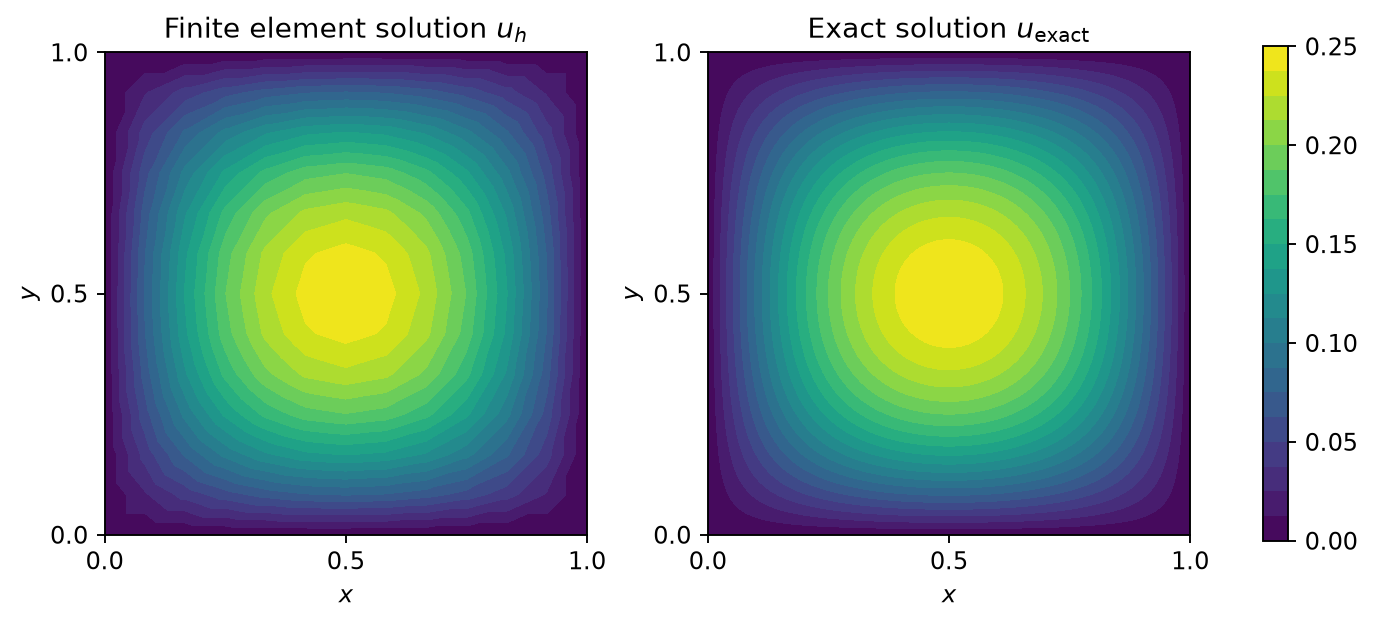

In [8]:
grid = np.linspace(0, 1, 101)
X, Y = np.meshgrid(grid, grid)
exact_values = 4 * X * (1 - X) * Y * (1 - Y)
levels = np.linspace(0, 0.25, 21)

fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3.5), dpi=170,
                                 layout="constrained")
colors = left.tricontourf(triangulation, u.x.array, levels=levels)
right.contourf(X, Y, exact_values, levels=levels)
left.set_title(r"Finite element solution $u_h$")
right.set_title(r"Exact solution $u_{\mathrm{exact}}$")
for ax in (left, right):
    ax.set(xlabel="$x$", ylabel="$y$", aspect="equal",
           xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
fig.colorbar(colors, ax=[left, right], ticks=[0, 0.05, 0.10, 0.15, 0.20, 0.25])
plt.show()